# Лабораторная работа 3. DBSCAN

`Исполнитель`: Александр Сорокин

`Данные`: Economics_of_Cities.csv

Иерархическая кластеризация этих данных — в лабораторной 1 (`ierarh_clustering.ipynb`), K-means — в лабораторной 2 (`kmeans_clustering.ipynb`). Здесь те же города разбиваем методом DBSCAN и сравниваем с ними.

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, fcluster

plt.style.use('ggplot')

## Данные

Те же 46 городов, что в лабораторных 1 и 2: Каир и Джакарта удалены из-за заглушек −9999. DBSCAN, как и K-means, считает евклидовы расстояния, поэтому признаки стандартизуем, иначе расстояние почти целиком определяли бы часы работы.

In [59]:
# sep=";" - разделитель столбцов, decimal="," - разделитель дробной части
df = pd.read_csv('Economics_of_Cities.csv', sep=';', decimal=',', index_col='City')
cols = ['Work', 'Price', 'Salary']

# -9999 - заглушка вместо пропуска
# превращаем в NaN и удаляем такие города
df = df.replace(-9999, np.nan).dropna()

X = pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=cols)
print(df.shape if df.shape == X.shape else None) # проверка

(46, 3)


Исходя из текста статьи 

Erich Schubert, Jörg Sander, Martin Ester, Hans-Peter Kriegel, and Xiaowei Xu. 2017. DBSCAN Revisited,
Revisited: Why and How You Should (Still) Use DBSCAN. ACM Trans. Database Syst. 42, 3, Article 19 (July
2017), 21 pages.

https://www.ccs.neu.edu/home/vip/teach/DMcourse/2_cluster_EM_mixt/notes_slides/revisitofrevisitDBSCAN.pdf

`The easier-to-set parameter of DBSCAN is the minPts parameter. Its purpose is to smooth the
density estimate, and for many datasets it can be kept at the default value of minPts = 4 (for
two-dimensional data) [16]. Sander et al. [40] suggest setting it to twice the dataset dimensionality, i.e., minPts = 2 · dim. For datasets that have a lot of noise, that are very large, that are highdimensional, or that have many duplicates it may improve results to increase minPts.`


Следует выбирать количество минимальных точек в радиусе как размерность датасета **dim * 2**, но также я нашел версию что можно выбирать их методом **dim + 1**, так как датасет небольшой с низким колиечеством шумов.

In [60]:
# для проверки можно сравнить два подхода

In [61]:
# Создадим функции для удобства
# Перебор eps:
def dbscan_metrics(data, min_samples, eps_values=np.round(np.arange(0.7, 1.3, 0.1), 2)):
    summary = []
    for eps in eps_values: # перебор радиусв
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(data) # запуск DBSCAN
        mask = labels != -1 # True - город в кластере, False - шум
        n_clusters = len(set(labels[mask])) # количество кластеров
        row = {
            'eps': eps, # радиус
            'n_clusters': n_clusters,
            'noise_fraction': np.mean(~mask), # доля шума
            'shape': pd.Series(labels).value_counts().sort_index().to_dict(), # размеры кластеров и шум
        }
        # метрики считаем без шума и только если кластеров хотя бы 2
        if n_clusters > 1:
            row['silhouette'] = silhouette_score(data[mask], labels[mask]) # чем больше, тем лучше
            row['davies_bouldin'] = davies_bouldin_score(data[mask], labels[mask]) # чем меньше, тем лучше
            row['calinski_harabasz'] = calinski_harabasz_score(data[mask], labels[mask]) # чем больше, тем лучше
        summary.append(row)
    return pd.DataFrame(summary).set_index('eps')

# k ближайших соседей
def k_neighbors(n_neighbors, data, eps_low, eps_high):
    dist, _ = NearestNeighbors(n_neighbors=n_neighbors).fit(data).kneighbors(data)
    k_dist = np.sort(dist[:, -1])  # расстояние до k-го соседа, по возрастанию
    
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(k_dist, color='blue')
    ax.axhspan(eps_low, eps_high, color='blue', alpha=0.3)  # закрашенная полоса от y=eps_low до y=eps_high
    ax.text(1, (eps_low + eps_high) / 2, 'Оптимальный $\\varepsilon$', fontsize=13, va='center')
    ax.set_xlim(0, len(k_dist) - 1)
    ax.set_xlabel('Города, отсортированные по расстоянию')
    ax.set_ylabel(f'Расстояние до {n_neighbors - 1}-го ближайшего соседа')
    ax.set_title('k-distance plot')
    plt.show()

## k = 4

,n_clusters,noise_fraction,shape,silhouette,davies_bouldin,calinski_harabasz
eps,,,,,,
0.7,3,0.239,"{-1: 11, 0: 17, 1: 4, 2: 14}",0.356,0.793,41.070
0.8,2,0.174,"{-1: 8, 0: 19, 1: 19}",0.512,0.722,57.122
0.9,1,0.174,"{-1: 8, 0: 38}",NaN,NaN,NaN
1.0,1,0.174,"{-1: 8, 0: 38}",NaN,NaN,NaN
1.1,1,0.152,"{-1: 7, 0: 39}",NaN,NaN,NaN
1.2,1,0.087,"{-1: 4, 0: 42}",NaN,NaN,NaN
1.3,1,0.022,"{-1: 1, 0: 45}",NaN,NaN,NaN


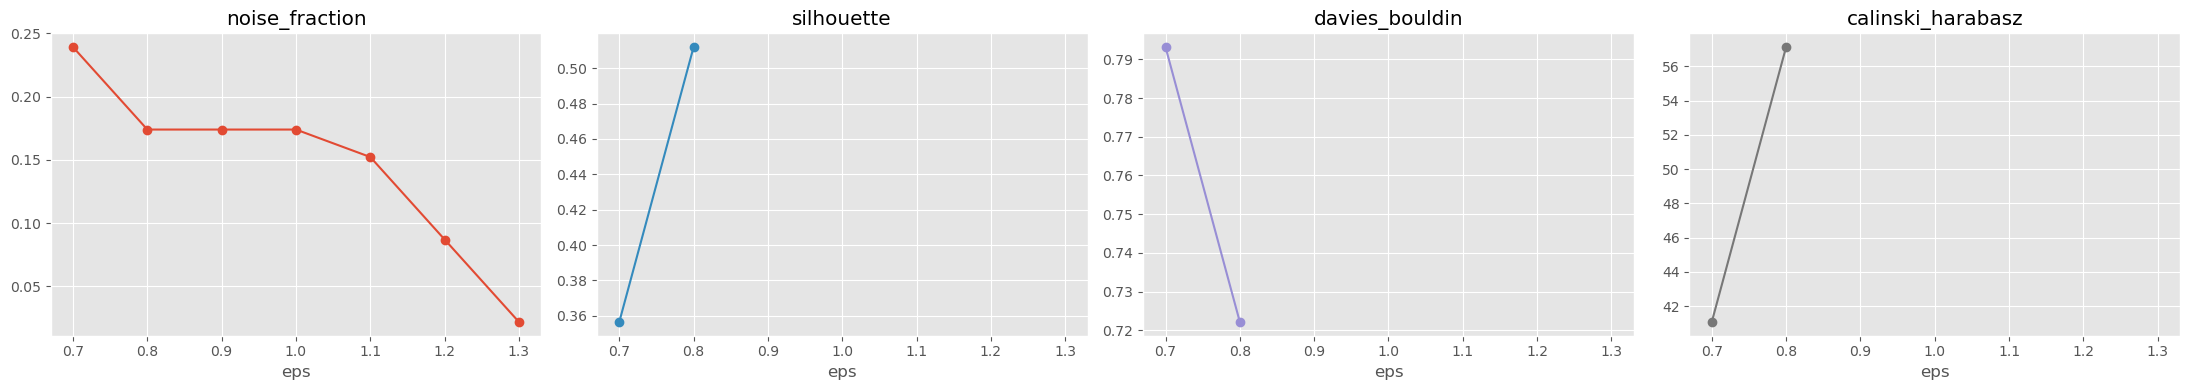

In [62]:
k = 4
dbscan_table = dbscan_metrics(X, min_samples=4)
display(dbscan_table.round(3))

num_cols = dbscan_table.drop(columns=['shape', 'n_clusters']) # shape не число, его не рисуем
num_cols.plot(subplots=True, layout=(1, 4), figsize=(22, 4), marker='o', legend=False,
              title=list(num_cols.columns), xlabel='eps')
plt.tight_layout()
plt.show()

In [63]:
# Количество шума становится равномерным при eps = 0.8, далее на спад, 
# то есть алгоритм притягивает все точки в кластеры, как в k-means

# Силуэт при eps = 0.8 максимальный (0.512, больше лучше) - точки ближе к своим кластерам, чем к чужим
# Индекс Дэвиса-Болдуина в локальном минимуме (0.72) при том же значении eps - разброс 
# внутри кластеров почти равен разбросу между кластерами

# Индекс Калински-Харабаша обратная функция индекса Дэвиса-Болдуина - больше лучше

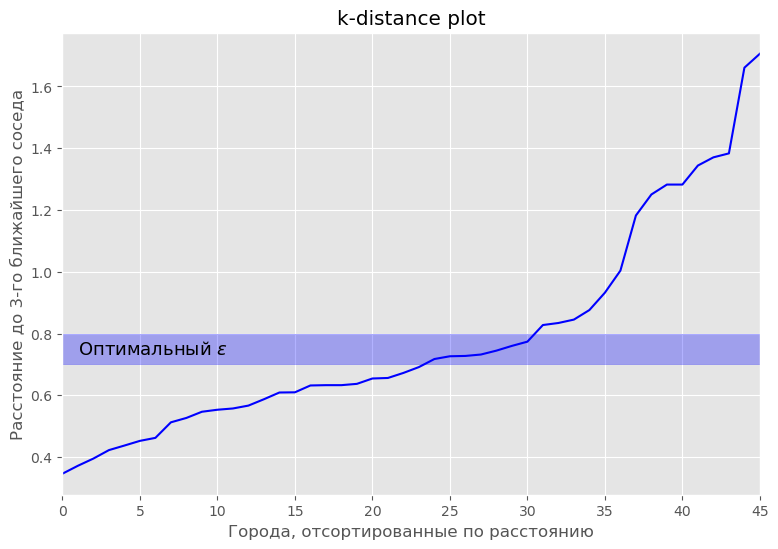

In [64]:
k_neighbors(k, X, 0.7, 0.8)

In [65]:
# Количество шума становится равномерным при eps = 0.8, далее на спад, 
# то есть алгоритм притягивает все точки в кластеры, как в k-means

# Силуэт при eps = 0.8 максимальный (0.512, больше лучше) - точки ближе к своим кластерам, чем к чужим
# Индекс Дэвиса-Болдуина в локальном минимуме (0.72) при том же значении eps - разброс 
# внутри кластеров почти равен разбросу между кластерами

# Индекс Калински-Харабаша обратная функция индекса Дэвиса-Болдуина - меньше лучше

In [66]:
# Создается DBSCAN
db = DBSCAN(eps=0.8, min_samples=4)
labels_4 = db.fit_predict(X)

# Создаётся булев массив длиной 46
core_mask = np.zeros(len(X), dtype=bool)
# db.core_sample_indices_ содержит индексы всех точек, которые DBSCAN признал ядровыми.
core_mask[db.core_sample_indices_] = True
# Булева маска всех точек, которым DBSCAN поставил метку -1.
noise_mask = labels_4 == -1
border_mask = (~core_mask) & (~noise_mask)

print('Ядровых точек:', core_mask.sum())
print('Граничных точек:', border_mask.sum())
print('Шумовых точек:', noise_mask.sum())
print('Кластеров без учёта шума:', len(set(labels_4)) - (1 if -1 in labels_4 else 0))

Ядровых точек: 31
Граничных точек: 7
Шумовых точек: 8
Кластеров без учёта шума: 2


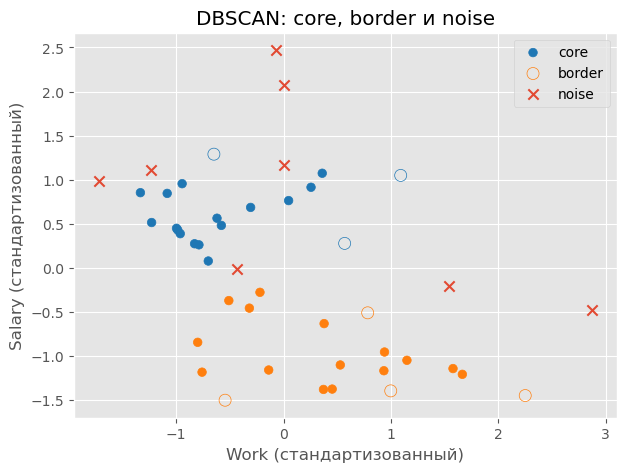

In [67]:
fig, ax = plt.subplots(figsize=(7, 5))

# диаграмма рассеяния строится по отработанным часам [0] и зарплате [2]
ax.scatter(X.iloc[core_mask, 0], X.iloc[core_mask, 2], c=plt.cm.tab10(labels_4[core_mask]), s=38, label='core')
ax.scatter(X.iloc[border_mask, 0], X.iloc[border_mask, 2], edgecolors=plt.cm.tab10(labels_4[border_mask]), s=75, marker='o', facecolors='none', label='border')
ax.scatter(X.iloc[noise_mask, 0], X.iloc[noise_mask, 2], marker='x', s=55, label='noise')

ax.set_title('DBSCAN: core, border и noise')
ax.set_xlabel('Work (стандартизованный)')
ax.set_ylabel('Salary (стандартизованный)')
ax.legend()
plt.show()

In [68]:
# добавим кластеры в датасет чтобы потом сравнить
df['cluster_4'] = labels_4

## k = 6

,n_clusters,noise_fraction,shape,silhouette,davies_bouldin,calinski_harabasz
eps,,,,,,
0.7,2,0.522,"{-1: 24, 0: 16, 1: 6}",0.677,0.424,67.603
0.8,2,0.261,"{-1: 12, 0: 18, 1: 16}",0.539,0.680,59.188
0.9,2,0.196,"{-1: 9, 0: 19, 1: 18}",0.518,0.720,57.585
1.0,1,0.196,"{-1: 9, 0: 37}",NaN,NaN,NaN
1.1,1,0.174,"{-1: 8, 0: 38}",NaN,NaN,NaN
1.2,1,0.109,"{-1: 5, 0: 41}",NaN,NaN,NaN
1.3,1,0.087,"{-1: 4, 0: 42}",NaN,NaN,NaN


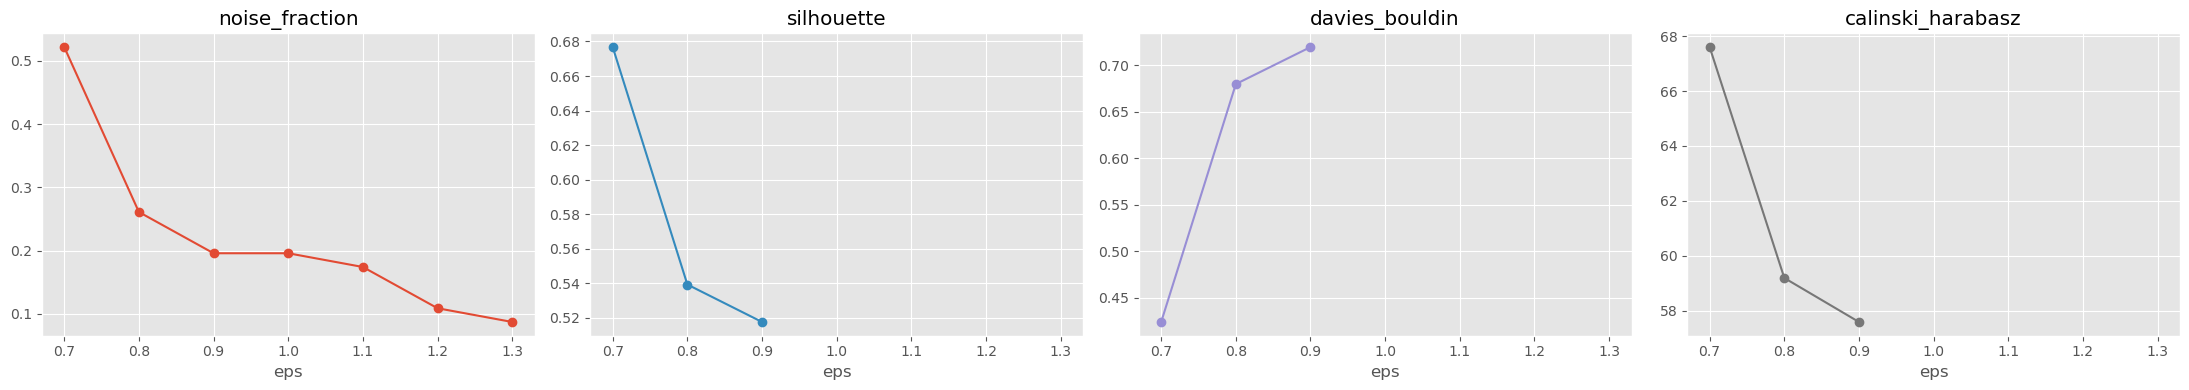

In [69]:
k = 6
dbscan_table = dbscan_metrics(X, min_samples=k)
display(dbscan_table.round(3))

num_cols = dbscan_table.drop(columns=['shape', 'n_clusters']) # shape не число, его не рисуем
num_cols.plot(subplots=True, layout=(1, 4), figsize=(22, 4), marker='o', legend=False,
              title=list(num_cols.columns), xlabel='eps')
plt.tight_layout()
plt.show()

In [70]:
# Количество шума становится равномерным при eps = 0.9, далее на спад, 
# то есть алгоритм притягивает все точки в кластеры, как в k-means

# Силуэт при eps = 0.9 минимальный (0.518, больше лучше) - точки ближе к своим кластерам, чем к чужим
# Индекс Дэвиса-Болдуина в локальном максимуме (0.72) при том же значении eps - разброс 
# внутри кластеров почти равен разбросу между кластерами

# Индекс Калински-Харабаша обратная функция индекса Дэвиса-Болдуина - меньше лучше

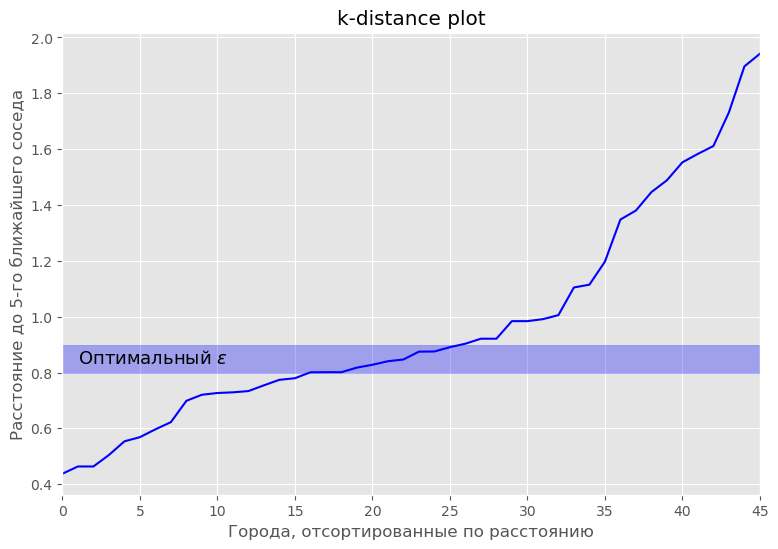

In [71]:
k_neighbors(k, X, 0.8, 0.9)

In [72]:
# Создается DBSCAN
db = DBSCAN(eps=0.9, min_samples=6)
labels_6 = db.fit_predict(X)

# Создаётся булев массив длиной 46
core_mask = np.zeros(len(X), dtype=bool)
# db.core_sample_indices_ содержит индексы всех точек, которые DBSCAN признал ядровыми.
core_mask[db.core_sample_indices_] = True
# Булева маска всех точек, которым DBSCAN поставил метку -1.
noise_mask = labels_6 == -1
border_mask = (~core_mask) & (~noise_mask)

print('Ядровых точек:', core_mask.sum())
print('Граничных точек:', border_mask.sum())
print('Шумовых точек:', noise_mask.sum())
print('Кластеров без учёта шума:', len(set(labels_6)) - (1 if -1 in labels_6 else 0))

Ядровых точек: 26
Граничных точек: 11
Шумовых точек: 9
Кластеров без учёта шума: 2


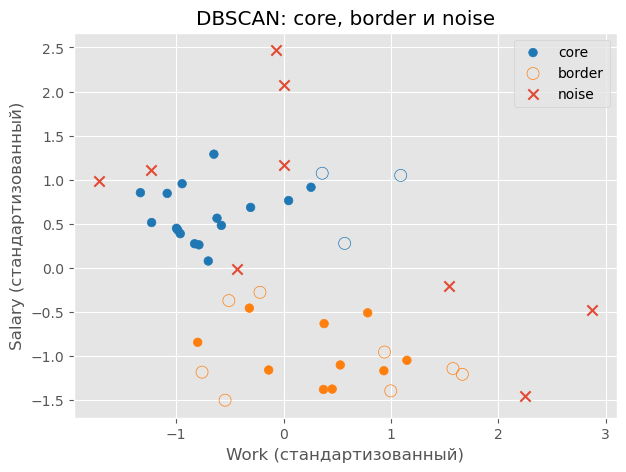

In [73]:
fig, ax = plt.subplots(figsize=(7, 5))

# диаграмма рассеяния строится по отработанным часам [0] и зарплате [2]
ax.scatter(X.iloc[core_mask, 0], X.iloc[core_mask, 2], c=plt.cm.tab10(labels_6[core_mask]), s=38, label='core')
ax.scatter(X.iloc[border_mask, 0], X.iloc[border_mask, 2], edgecolors=plt.cm.tab10(labels_6[border_mask]), s=75, marker='o', facecolors='none', label='border')
ax.scatter(X.iloc[noise_mask, 0], X.iloc[noise_mask, 2], marker='x', s=55, label='noise')

ax.set_title('DBSCAN: core, border и noise')
ax.set_xlabel('Work (стандартизованный)')
ax.set_ylabel('Salary (стандартизованный)')
ax.legend()
plt.show()

In [74]:
# посмотрим какие города попали в кластеры
df['cluster_6'] = labels_6

# какие города разошлись?
df[df['cluster_4'] != df['cluster_6']]

,Work,Price,Salary,cluster_4,cluster_6
City,,,,,
Manila,2268.0,40.0,4.0,1,-1


## Сравнение с K-means и иерархической кластеризацией

In [75]:
from sklearn.metrics import adjusted_rand_score

# Уорд и K-means на тех же стандартизованных X, с теми же параметрами, что в лабах 1 и 2
link = linkage(X, method='ward')
df['ward_2'] = fcluster(link, 2, criterion='maxclust') # Уорд, 2 кластера
df['ward_4'] = fcluster(link, 4, criterion='maxclust') # Уорд, 4 кластера

# у K-means номера кластеров случайные, перенумеруем по убыванию зарплаты, как в лабе 2
def kmeans_labels(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    order = df.groupby(km)['Salary'].mean().sort_values(ascending=False).index
    return pd.Series(km, index=df.index).map({old: new for new, old in enumerate(order, start=1)})

df['km_2'] = kmeans_labels(2) # K-means, 2 кластера
df['km_4'] = kmeans_labels(4) # K-means, 4 кластера

# основной вариант DBSCAN: min_samples=6, eps=0.9
main = 'cluster_6'

# шум у DBSCAN подпишем словом, чтобы в таблицах было видно
df['dbscan'] = df[main].map(lambda c: 'шум' if c == -1 else f'кластер {c}')

df.groupby('ward_4')[cols].mean().round(1) # проверка: нумерация Уорда как в лабе 1 (1 - самые богатые)

,Work,Price,Salary
ward_4,,,
1,1780.5,108.6,71.3
2,1792.0,77.5,55.2
3,1798.9,50.9,19.2
4,2082.4,53.1,14.9


In [76]:
# таблицы сопряжённости: в какие кластеры Уорда и K-means попали города из каждого кластера DBSCAN
for col, name in [('ward_2', 'Уорд, k=2'), ('km_2', 'K-means, k=2'),
                  ('ward_4', 'Уорд, k=4'), ('km_4', 'K-means, k=4')]:
    print(name)
    display(pd.crosstab(df['dbscan'], df[col], rownames=['DBSCAN'], colnames=[name]))

Уорд, k=2


"Уорд, k=2",1,2
DBSCAN,,
кластер 0,19,0
кластер 1,0,18
шум,6,3


K-means, k=2


"K-means, k=2",1,2
DBSCAN,,
кластер 0,19,0
кластер 1,0,18
шум,6,3


Уорд, k=4


"Уорд, k=4",1,2,3,4
DBSCAN,,,,
кластер 0,0,19,0,0
кластер 1,0,0,7,11
шум,6,0,0,3


K-means, k=4


"K-means, k=4",1,2,3,4
DBSCAN,,,,
кластер 0,2,17,0,0
кластер 1,0,0,11,7
шум,6,0,0,3


In [77]:
# какие города DBSCAN счёл шумом и где они были у Уорда и K-means
df.loc[df[main] == -1, cols + ['ward_4', 'km_4']]

,Work,Price,Salary,ward_4,km_4
City,,,,,
Geneva,1880.0,95.9,90.3,1,1
Helsinki,1667.0,113.6,66.6,1,1
Hong_Kong,2375.0,63.8,27.8,4,4
Manila,2268.0,40.0,4.0,4,4
Oslo,1583.0,115.5,63.7,1,1
Stockholm,1805.0,111.3,39.2,1,1
Taipei,2145.0,84.3,34.5,4,4
Tokyo,1880.0,115.0,68.0,1,1
Zurich,1868.0,100.0,100.0,1,1


In [78]:
# ARI - насколько совпадают два разбиения: 1 - полностью, около 0 - как случайно
# номера кластеров ему не важны, перенумеровывать не надо
no_noise = df[main] != -1 # маска: города, которые DBSCAN отнёс к кластерам
methods = ['ward_2', 'km_2', 'ward_4', 'km_4', 'cluster_4']

ari = pd.DataFrame({
    # шум считаем отдельной группой
    'ARI, все 46 городов': [adjusted_rand_score(df[main], df[c]) for c in methods],
    # шум выкидываем
    'ARI, без шума': [adjusted_rand_score(df.loc[no_noise, main], df.loc[no_noise, c]) for c in methods],
}, index=['Уорд, k=2', 'K-means, k=2', 'Уорд, k=4', 'K-means, k=4', 'DBSCAN, min_samples=4'])
ari.round(3)

,"ARI, все 46 городов","ARI, без шума"
"Уорд, k=2",0.639,1.000
"K-means, k=2",0.639,1.000
"Уорд, k=4",0.716,0.767
"K-means, k=4",0.632,0.663
"DBSCAN, min_samples=4",0.945,1.000


In [79]:
# силуэт честно: у DBSCAN шум выкинут, поэтому всех считаем на одних и тех же городах без шума
sil = pd.DataFrame({
    'Силуэт, без шума': [silhouette_score(X[no_noise], df.loc[no_noise, c])
                         for c in [main, 'ward_2', 'km_2', 'ward_4', 'km_4']],
    'Силуэт, все 46 городов': [np.nan] + [silhouette_score(X, df[c])
                                          for c in ['ward_2', 'km_2', 'ward_4', 'km_4']],
}, index=['DBSCAN', 'Уорд, k=2', 'K-means, k=2', 'Уорд, k=4', 'K-means, k=4'])
sil.round(3)

,"Силуэт, без шума","Силуэт, все 46 городов"
DBSCAN,0.518,NaN
"Уорд, k=2",0.518,0.470
"K-means, k=2",0.518,0.470
"Уорд, k=4",0.446,0.355
"K-means, k=4",0.230,0.340


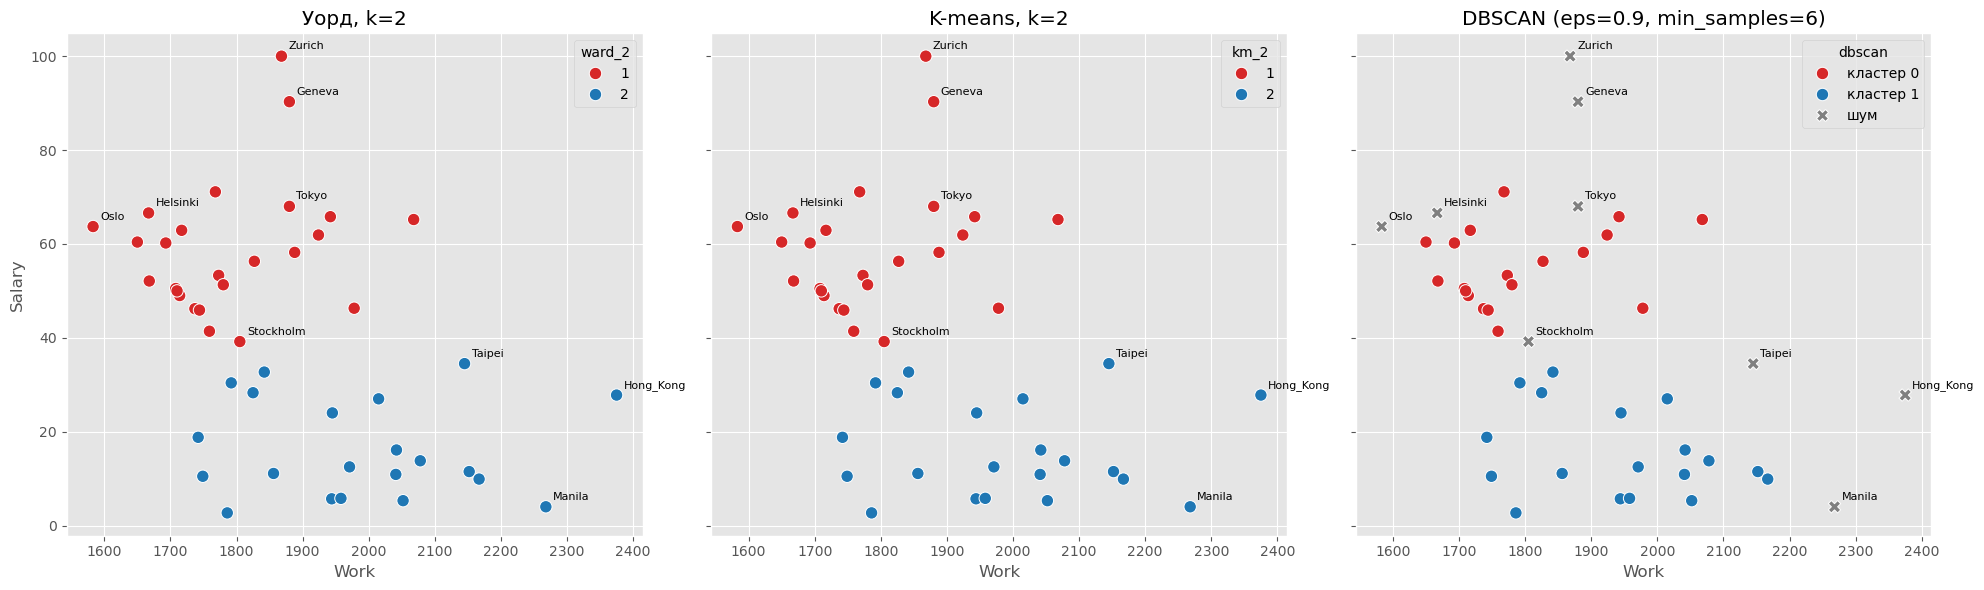

In [80]:
# три метода рядом на Work x Salary
palette = {'кластер 0': 'tab:red', 'кластер 1': 'tab:blue', 'шум': 'gray'} # шум серый
markers = {'кластер 0': 'o', 'кластер 1': 'o', 'шум': 'X'}                # шум крестиком

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, col, title in zip(axes, ['ward_2', 'km_2', 'dbscan'],
                          ['Уорд, k=2', 'K-means, k=2', 'DBSCAN (eps=0.9, min_samples=6)']): # наиболее эффективный dbscan с min_samples=6, eps=0.9
    if col == 'dbscan':
        sns.scatterplot(data=df, x='Work', y='Salary', hue=col, style=col,
                        palette=palette, markers=markers, s=80, ax=ax)
    else:
        sns.scatterplot(data=df, x='Work', y='Salary', hue=col, palette=['tab:red', 'tab:blue'], s=80, ax=ax)
    # подписываем шумовые города на всех трёх графиках, чтобы было видно, где они у других методов
    for city, row in df[df[main] == -1].iterrows():
        ax.annotate(city, (row['Work'], row['Salary']), fontsize=8, xytext=(5, 5), textcoords='offset points')
    ax.set_title(title)
plt.tight_layout()
plt.show()

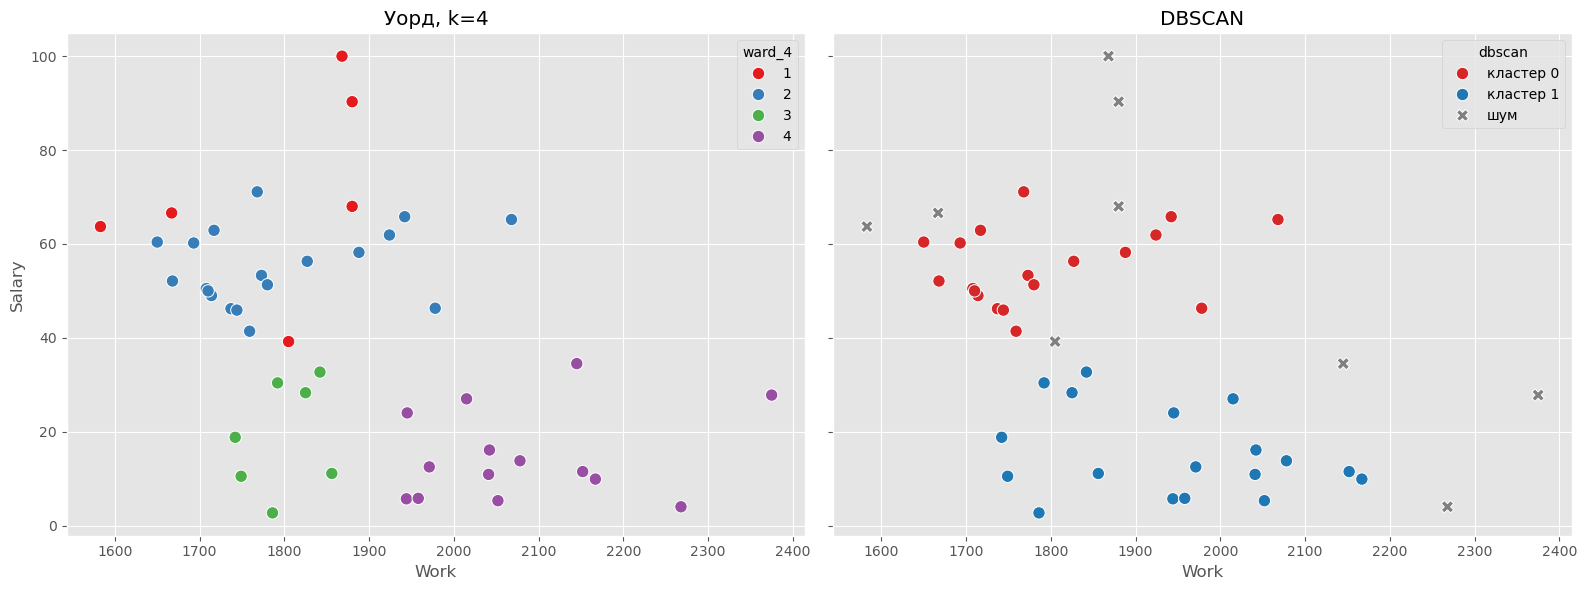

In [81]:
# то же с 4 кластерами Уорда: видно, что DBSCAN склеил 3 и 4
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
sns.scatterplot(data=df, x='Work', y='Salary', hue=df['ward_4'].astype(str),
                hue_order=['1', '2', '3', '4'], palette='Set1', s=80, ax=axes[0])
axes[0].set_title('Уорд, k=4')
sns.scatterplot(data=df, x='Work', y='Salary', hue='dbscan', style='dbscan',
                palette=palette, markers=markers, s=80, ax=axes[1])
axes[1].set_title('DBSCAN')
plt.tight_layout()
plt.show()

## Выводы

Признаки стандартизовали, как в лабах 1 и 2.

основным взяли min_samples = 6, eps = 0.9. eps подбирали по графику k-distance и метрикам: силуэт 0.518, Davies-Bouldin 0.72, шум 20%. При меньших eps почти всё становится шумом, при больших все города сливаются в один кластер.

DBSCAN нашёл 2 кластера (19 и 18 городов) и 9 точек шума. Кластер 0 это развитые города (ровно кластер 2 Уорда), кластер 1 небогатые (кластеры 3 и 4 Уорда без Гонконга, Тайбэя и Манилы).

Если не считать шум, DBSCAN полностью совпал с Уордом и K-means при k = 2 (ARI = 1, силуэт у всех 0.512). То есть деление на богатых и бедных устойчивое, его находят три метода с разной логикой.

В шум попали 6 самых богатых городов (Цюрих, Женева, Токио, Осло, Стокгольм, Хельсинки, это весь кластер 1 Уорда) и Гонконг с Тайбэем. Самые богатые далеко друг от друга и плотной группы не образуют, у Уорда этот кластер тоже был самым рыхлым (силуэт 0.22). Гонконг и Тайбэй выделяются очень длинным рабочим годом.

Небогатых DBSCAN на 2 группы не делит, как Уорд при k = 4. Между ними нет разрыва в плотности: пограничные города (Йоханнесбург, Мехико, Найроби, Буэнос-Айрес) связывают их в одну цепочку.

DBSCAN не требует заранее задавать число кластеров и сам находит выбросы, но сильно зависит от eps, рабочий диапазон узкий, 0.75–0.8. Для этих данных он подтверждает результат k = 2 и показывает, какие города не похожи ни на кого.